In [ ]:
# Paths (relative to the repository root, so the notebooks run on any machine)
# Expected layout:  <repo>/notebooks/ (this file), <repo>/data/, <repo>/models/,
#                   <repo>/figures/, <repo>/results/, <repo>/feature_importance/
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FI_DIR = ROOT / "feature_importance"
for _d in (DATA_DIR, MODELS_DIR, FIG_DIR, RESULTS_DIR, FI_DIR):
    _d.mkdir(parents=True, exist_ok=True)


In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(str(DATA_DIR / "MetalCytoToxDB.csv"))
df["row_id"] = df.index

In [2]:
df = df[
[
"row_id",
"SMILES_Ligands",
"IC50_Dark_value",
"Cell_line",
"Metal",
"Charge_complex",
"Oxidation_state",
"Atomic_number",
"Valence_e",
"Time(h)",
"Year"
]
]

df.head()

,row_id,SMILES_Ligands,IC50_Dark_value,Cell_line,Metal,Charge_complex,Oxidation_state,Atomic_number,Valence_e,Time(h),Year
0,0,N#Cc1ccc(C(c2ccc(C#N)cc2)n2cncn2)cc1.N#Cc1ccc(...,36.00,MCF-7,Ru,1,2,44,8,24.0,2012
1,1,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,19.58,MCF-7,Ru,0,2,44,8,72.0,2012
2,2,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,13.98,HCT-116,Ru,0,2,44,8,72.0,2012
3,3,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,23.38,A2780,Ru,0,2,44,8,72.0,2012
4,4,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,27.00,CP8,Ru,0,2,44,8,72.0,2012


In [3]:
df.isnull().sum()

row_id               0
SMILES_Ligands       0
IC50_Dark_value      0
Cell_line            0
Metal                0
Charge_complex       0
Oxidation_state      0
Atomic_number        0
Valence_e            0
Time(h)            189
Year                 0
dtype: int64

In [4]:
df.shape

(26801, 11)

In [5]:
print(df.duplicated().sum())

0


In [6]:
duplicates = df[df.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [row_id, SMILES_Ligands, IC50_Dark_value, Cell_line, Metal, Charge_complex, Oxidation_state, Atomic_number, Valence_e, Time(h), Year]
Index: []


In [7]:
df.shape

(26801, 11)

In [8]:
df["IC50_Dark_value"].describe()

count    26801.000000
mean        66.069065
std        131.509254
min          0.002000
25%          5.700000
50%         23.000000
75%         92.560000
max       8157.000000
Name: IC50_Dark_value, dtype: float64

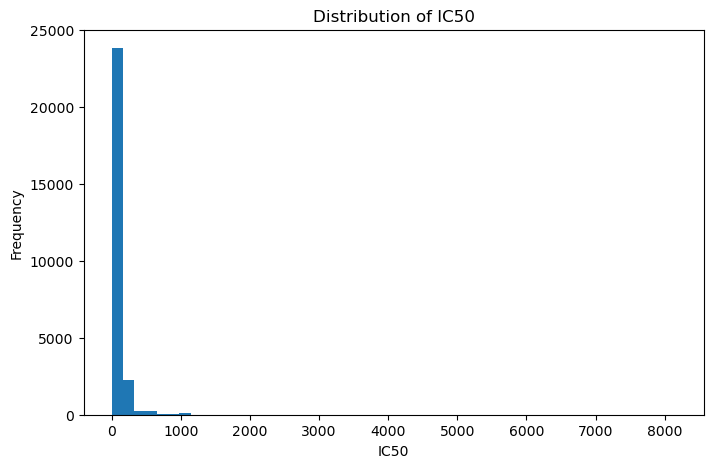

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["IC50_Dark_value"], bins=50)

plt.xlabel("IC50")
plt.ylabel("Frequency")

plt.title("Distribution of IC50")

plt.show()

In [10]:
print("Minimum IC50:", df["IC50_Dark_value"].min())

print("Zero values:", (df["IC50_Dark_value"] == 0).sum())

print("Negative values:", (df["IC50_Dark_value"] < 0).sum())

Minimum IC50: 0.002
Zero values: 0
Negative values: 0


In [11]:
df["pIC50"] = -np.log10(df["IC50_Dark_value"] * 1e-6)

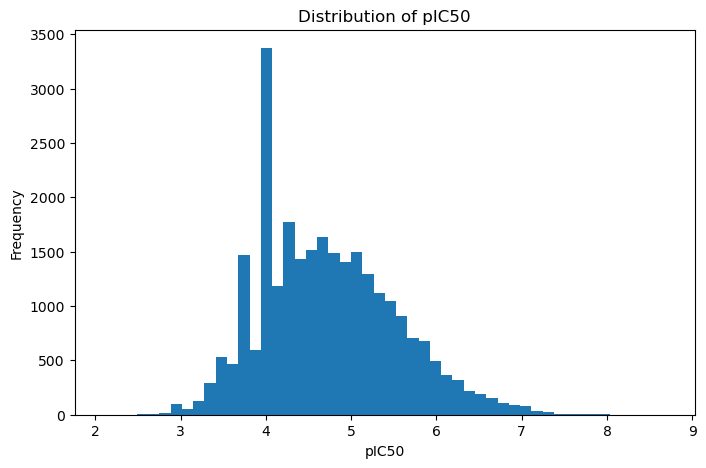

In [12]:
plt.figure(figsize=(8,5))

plt.hist(df["pIC50"], bins=50)

plt.xlabel("pIC50")
plt.ylabel("Frequency")
plt.title("Distribution of pIC50")

plt.show()

In [13]:
df[["row_id", "pIC50"]].to_csv(str(DATA_DIR / "pIC50.csv"), index = False)